In [1]:
import musdb

In [2]:
import zipfile, os
 
ZIP_PATH   = "./musdb18hq.zip"          # ← change to your zip path
EXTRACT_DIR = "./musdb18"           # where to unzip
 
if not os.path.isdir(EXTRACT_DIR):
    print("Extracting...")
    with zipfile.ZipFile(ZIP_PATH, 'r') as z:
        z.extractall(EXTRACT_DIR)
    print("Done.")
else:
    print("Already extracted, skipping.")
 
# Show top-level folder structure
for root, dirs, files in os.walk(EXTRACT_DIR):
    depth = root.replace(EXTRACT_DIR, '').count(os.sep)
    if depth > 1:
        break
    indent = '  ' * depth
    print(f"{indent}{os.path.basename(root)}/")
    if depth == 1:
        for f in files[:3]:
            print(f"  {indent}{f}")

Extracting...
Done.
musdb18/
  train/


In [3]:
# Set is_wav=True if your zip contains .wav stems (musdb18-HQ)
# Leave is_wav=False for the standard .mp4/stem format
mus = musdb.DB(root=EXTRACT_DIR, is_wav=True)
 
print(f"Total tracks : {len(mus.tracks)}")
print(f"Train tracks : {len(mus.load_mus_tracks(subsets='train'))}")
print(f"Test  tracks : {len(mus.load_mus_tracks(subsets='test'))}")

Total tracks : 150
Train tracks : 100
Test  tracks : 50


In [12]:
track = mus.tracks[1]
 
print("Track name  :", track.name)
print("Sample rate :", track.rate, "Hz")
print("Duration    :", round(track.audio.shape[0] / track.rate, 2), "s")
print("Stems       :", list(track.stems_dict.keys()) if hasattr(track, 'stems_dict') else [s for s in track.targets])
print("\nAvailable targets:")
for name, target in track.targets.items():
    print(f"  {name}")

Track name  : ANiMAL - Clinic A
Sample rate : 44100 Hz
Duration    : 238.05 s
Stems       : ['vocals', 'drums', 'bass', 'other', 'accompaniment', 'linear_mixture']

Available targets:
  vocals
  drums
  bass
  other
  accompaniment
  linear_mixture


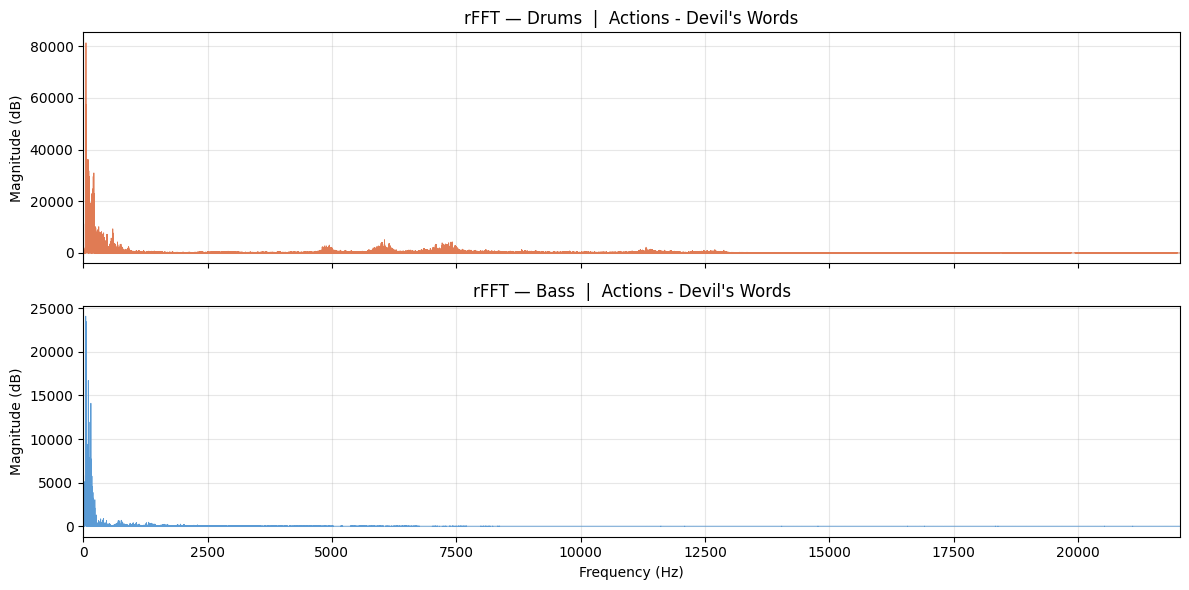

In [24]:
import matplotlib.pyplot as plt
import numpy as np
sr = track.rate
stems_to_plot = {'drums': '#e07b54', 'bass': '#5b9bd5'}

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

for ax, (stem, color) in zip(axes, stems_to_plot.items()):
    audio_mono = track.targets[stem].audio[:, 0]   # left channel, mono

    # compute rFFT
    N      = len(audio_mono)
    rfft   = np.fft.rfft(audio_mono)
    freqs  = np.fft.rfftfreq(N, d=1.0 / sr)       # frequency axis in Hz
    mag_db = 20 * np.log10(np.abs(rfft) + 1e-9)   # magnitude in dB

    ax.plot(freqs, np.abs(rfft), color=color, lw=0.6)
    ax.set_ylabel("Magnitude (dB)")
    ax.set_title(f"rFFT — {stem.capitalize()}  |  {track.name}")
    ax.set_xlim(0, sr / 2)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Frequency (Hz)")
plt.tight_layout()
plt.show()